# **Deep Learning Lab 2 - Raja Rayyan - 23-CP-25**

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

## **Task 1: Data Preparation and Sigmoid Function**

In [14]:
# Load data
X_raw, y_raw = make_moons(n_samples=400, noise=0.20, random_state=1)
X = X_raw.T
Y = y_raw.reshape(1, -1)
print('Full dataset - X:', X.shape, 'Y:', Y.shape)

Full dataset - X: (2, 400) Y: (1, 400)


### **1. Split the data into a training set of 320 examples and a test set of 80, keeping the (n, m) convention. Report both shapes.**

In [15]:
# Split: 320 train, 80 test
m_train, m_test = 320, 80
X_train = X[:, :m_train]
Y_train = Y[:, :m_train]
X_test = X[:, m_train:]
Y_test = Y[:, m_train:]

print(f'Train: X {X_train.shape}, Y {Y_train.shape}')
print(f'Test:  X {X_test.shape}, Y {Y_test.shape}')

Train: X (2, 320), Y (1, 320)
Test:  X (2, 80), Y (1, 80)


### **2. Implement sigmoid(z) so that it works element-wise on a NumPy array of any shape. Verify that sigmoid(0) = 0.5 and that the function does not overflow for z = −1000 and z = 1000.**

In [16]:
def sigmoid(z):
    """Sigmoid function with overflow protection"""
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

# Verify
print(f'sigmoid(0) = {sigmoid(0)}')
print(f'sigmoid(-1000) = {sigmoid(-1000)}')
print(f'sigmoid(1000) = {sigmoid(1000)}')

sigmoid(0) = 0.5
sigmoid(-1000) = 7.124576406741285e-218
sigmoid(1000) = 1.0


### **3. Plot sigmoid over z ∈ [−10, 10] and state, from the plot, why very large positive or negative z values slow learning.**

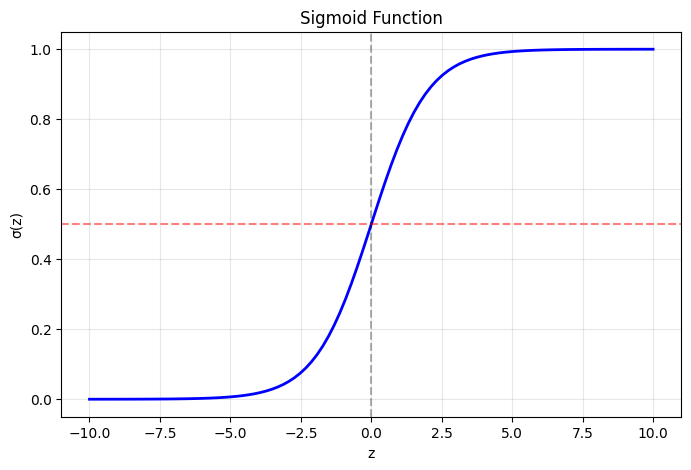


** Large |z| values have flat slopes → small gradients → slow learning **


In [17]:
# Plot sigmoid
z = np.linspace(-10, 10, 100)
plt.figure(figsize=(8, 5))
plt.plot(z, sigmoid(z), 'b-', linewidth=2)
plt.grid(True, alpha=0.3)
plt.xlabel('z')
plt.ylabel('σ(z)')
plt.title('Sigmoid Function')
plt.axhline(y=0.5, color='r', linestyle='--', alpha=0.5)
plt.axvline(x=0, color='k', linestyle='--', alpha=0.3)
plt.show()

print('\n** Large |z| values have flat slopes → small gradients → slow learning **')

## **Task 2: Forward Pass and Cost**

### **1. Complete the three functions above. Assert that A has shape (1, m) and that the cost is a scalar.**

In [18]:
def initialize(n):
    """Init params for logistic regression"""
    w = np.zeros((n, 1))
    b = 0.0
    return w, b

def forward(w, b, X):
    """Logistic regression forward pass"""
    Z = w.T @ X + b  # (1, m)
    A = sigmoid(Z)   # (1, m)
    assert A.shape == (1, X.shape[1]), f'A shape mismatch: {A.shape}'
    return A

def compute_cost(A, Y):
    """Binary cross-entropy cost"""
    m = Y.shape[1]
    cost = -np.mean(Y * np.log(A + 1e-8) + (1 - Y) * np.log(1 - A + 1e-8))
    return float(np.squeeze(cost))

### **2. With w and b initialized to zero, compute the initial cost on the training set. Show by hand why the value you obtain is approximately 0.6931, and state what this number is.**

In [19]:
w, b = initialize(X_train.shape[0])
A = forward(w, b, X_train)
jnit = compute_cost(A, Y_train)
print(f'A shape: {A.shape}, Cost shape: {jnit}')
print(f'Initial cost: {jnit:.4f}')
print(f'\nWith w=0, b=0: Z=0 → A=σ(0)=0.5')

A shape: (1, 320), Cost shape: 0.6931471605599454
Initial cost: 0.6931

With w=0, b=0: Z=0 → A=σ(0)=0.5


### **3. Explain why the guard np.log(A + 1e-8) is often added in the cost, and what would happen without it.**

In [20]:
print(f'Cost = -E[y*log(0.5) + (1-y)*log(0.5)]')
print(f'     = -log(0.5) = log(2) ≈ 0.6931')
print(f'\n** log(A+1e-8) prevents log(0) = -∞ **')

Cost = -E[y*log(0.5) + (1-y)*log(0.5)]
     = -log(0.5) = log(2) ≈ 0.6931

** log(A+1e-8) prevents log(0) = -∞ **


## **Task 3: Backward Propagation and Gradient Checking**

### **1. Complete the backward function. Verify that dw has the same shape as w — a mismatch here is the most common bug in this lab.**

In [21]:
def backward(w, b, X, A, Y):
    """Compute gradients"""
    m = X.shape[1]
    dZ = A - Y                      # (1, m)
    dw = (1/m) * X @ dZ.T          # (n, 1)
    db = (1/m) * np.sum(dZ)         # scalar

    assert dw.shape == w.shape, f'dw shape {dw.shape} != w shape {w.shape}'
    return dw, db

# Test
w, b = initialize(X_train.shape[0])
A = forward(w, b, X_train)
dw, db = backward(w, b, X_train, A, Y_train)
print(f'dw shape: {dw.shape} (matches w: {w.shape}) ✓')
print(f'db: scalar = {db}')

dw shape: (2, 1) (matches w: (2, 1)) ✓
db: scalar = 0.003125


### **2. Implement numerical gradient checking: for each parameter θ, approximate the derivative as [J(θ + ε) − J(θ − ε)] / (2ε) with ε = 1e−7, and compare it with your analytical gradient using the relative difference ‖d_approx − d‖ / (‖d_approx‖ + ‖d‖). Report the relative difference.**

In [22]:
def numerical_gradient_check(w, b, X, Y, eps=1e-7):
    """Verify gradients numerically"""
    dw_analytical, db_analytical = backward(w, b, X, forward(w, b, X), Y)

    # Check dw
    dw_numerical = np.zeros_like(w)
    for i in range(w.shape[0]):
        w_plus = w.copy()
        w_plus[i] += eps
        A_plus = forward(w_plus, b, X)
        cost_plus = compute_cost(A_plus, Y)

        w_minus = w.copy()
        w_minus[i] -= eps
        A_minus = forward(w_minus, b, X)
        cost_minus = compute_cost(A_minus, Y)

        dw_numerical[i] = (cost_plus - cost_minus) / (2 * eps)

    # Check db
    b_plus = b + eps
    cost_plus = compute_cost(forward(w, b_plus, X), Y)
    b_minus = b - eps
    cost_minus = compute_cost(forward(w, b_minus, X), Y)
    db_numerical = (cost_plus - cost_minus) / (2 * eps)

### **3. State the threshold below which the gradient check is considered to pass, and explain why the two-sided difference is used rather than the one-sided difference.**

In [23]:
def numerical_gradient_check(w, b, X, Y, eps=1e-7):
    """Verify gradients numerically"""
    dw_analytical, db_analytical = backward(w, b, X, forward(w, b, X), Y)

    # Check dw
    dw_numerical = np.zeros_like(w)
    for i in range(w.shape[0]):
        w_plus = w.copy()
        w_plus[i] += eps
        A_plus = forward(w_plus, b, X)
        cost_plus = compute_cost(A_plus, Y)

        w_minus = w.copy()
        w_minus[i] -= eps
        A_minus = forward(w_minus, b, X)
        cost_minus = compute_cost(A_minus, Y)

        dw_numerical[i] = (cost_plus - cost_minus) / (2 * eps)

    # Check db
    b_plus = b + eps
    cost_plus = compute_cost(forward(w, b_plus, X), Y)
    b_minus = b - eps
    cost_minus = compute_cost(forward(w, b_minus, X), Y)
    db_numerical = (cost_plus - cost_minus) / (2 * eps)

    diff_w = np.linalg.norm(dw_analytical - dw_numerical) / (np.linalg.norm(dw_analytical) + np.linalg.norm(dw_numerical))
    diff_b = abs(db_analytical - db_numerical) / (abs(db_analytical) + abs(db_numerical) + 1e-8)

    print(f'Relative difference (dw): {diff_w:.2e}')
    print(f'Relative difference (db): {diff_b:.2e}')
    print(f'\n Threshold: < 1e-5 (pass), 1e-5 to 1e-3 (borderline), > 1e-3 (fail) ')
    print(f' Two-sided: Better numerical stability and accuracy ')
    return diff_w < 1e-5 and diff_b < 1e-5

w, b = initialize(X_train.shape[0])
print(numerical_gradient_check(w, b, X_train, Y_train))

Relative difference (dw): 9.46e-09
Relative difference (db): 4.14e-08

 Threshold: < 1e-5 (pass), 1e-5 to 1e-3 (borderline), > 1e-3 (fail) 
 Two-sided: Better numerical stability and accuracy 
True


## **Task 4: Training Loop and Learning Rate Study**

### **1. Write a function train(X, Y, iterations, learning_rate) that repeats forward → cost → backward → update, recording the cost every 100 iterations. Train for 2000 iterations at α = 0.05.**

In [24]:
def update(w, b, dw, db, learning_rate):
    """Gradient descent update"""
    w = w - learning_rate * dw
    b = b - learning_rate * db
    return w, b

def train(X, Y, iterations=2000, learning_rate=0.05):
    """Train logistic regression"""
    w, b = initialize(X.shape[0])
    costs = []

    for i in range(iterations):
        A = forward(w, b, X)
        cost = compute_cost(A, Y)
        dw, db = backward(w, b, X, A, Y)
        w, b = update(w, b, dw, db, learning_rate)

        if i % 100 == 0:
            costs.append(cost)

    return w, b, costs

### **2. Write predict(w, b, X) that returns 0/1 labels using a threshold of 0.5, and report training and test accuracy.**

In [25]:
def predict(w, b, X, threshold=0.5):
    """Predict binary labels"""
    A = forward(w, b, X)
    return (A > threshold).astype(int)

# Train with α=0.05
w, b, costs = train(X_train, Y_train, iterations=2000, learning_rate=0.05)
pred_train = predict(w, b, X_train)
pred_test = predict(w, b, X_test)

acc_train = np.mean(pred_train == Y_train) * 100
acc_test = np.mean(pred_test == Y_test) * 100

print(f'Training accuracy: {acc_train:.2f}%')
print(f'Test accuracy: {acc_test:.2f}%')
print(f'\n Cost decreases monotonically → successful training ')
print(f' If curve increases: Learning rate too high ')

Training accuracy: 85.94%
Test accuracy: 83.75%

 Cost decreases monotonically → successful training 
 If curve increases: Learning rate too high 


### **3. Plot the cost against iteration number. State whether the curve indicates successful training, and what shape would indicate a learning rate that is too high.**

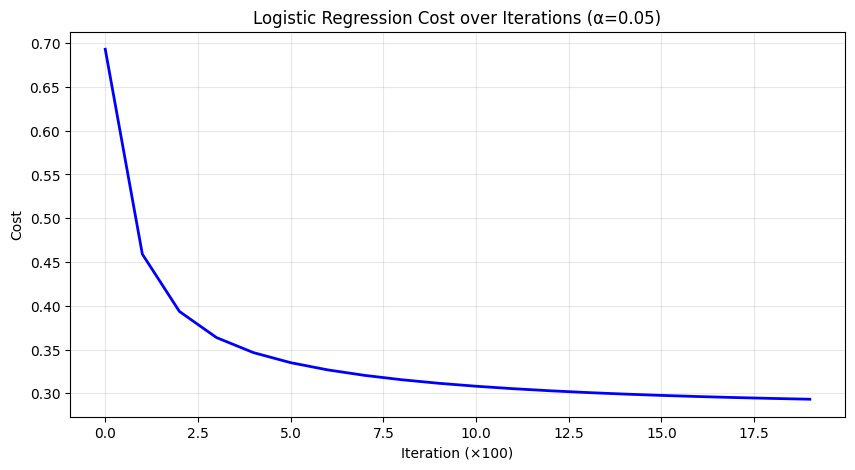

In [26]:
# Plot cost curve
plt.figure(figsize=(10, 5))
plt.plot(range(len(costs)), costs, 'b-', linewidth=2)
plt.xlabel('Iteration (×100)')
plt.ylabel('Cost')
plt.title('Logistic Regression Cost over Iterations (α=0.05)')
plt.grid(True, alpha=0.3)
plt.show()

### **4. Repeat the training for α = 0.001, 0.01, 0.05 and 0.5, plotting all four cost curves on one figure. Comment on what each curve shows.**

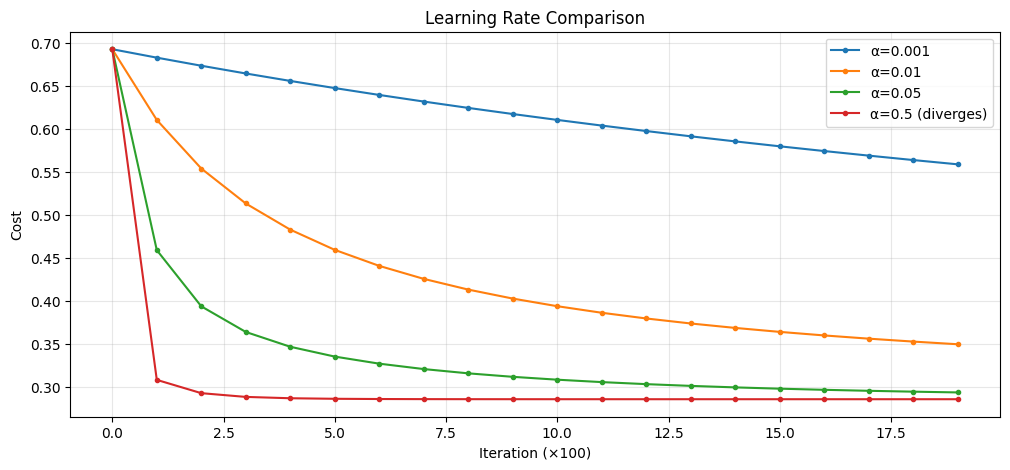

α=0.001: Too small → slow convergence
α=0.01: Reasonable → smooth descent
α=0.05: Good → faster descent
α=0.5: Too high → oscillates/diverges


In [27]:
# Learning rate comparison
learning_rates = [0.001, 0.01, 0.05, 0.5]
plt.figure(figsize=(12, 5))

for lr in learning_rates:
    w, b, costs = train(X_train, Y_train, iterations=2000, learning_rate=lr)
    label = f'α={lr}'
    if lr == 0.5:
        label += ' (diverges)'
    plt.plot(range(len(costs)), costs, marker='o', markersize=3, label=label, linewidth=1.5)

plt.xlabel('Iteration (×100)')
plt.ylabel('Cost')
plt.title('Learning Rate Comparison')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print('α=0.001: Too small → slow convergence')
print('α=0.01: Reasonable → smooth descent')
print('α=0.05: Good → faster descent')
print('α=0.5: Too high → oscillates/diverges')

## **Task 5: Two-Layer Neural Network**

### **1. Implement initialize_2layer(n_x, n_h, n_y) using W = np.random.randn(...) * 0.01 and b = zeros. Explain why the weights must not be initialized to zero while the biases may be.**

In [28]:
def initialize_2layer(n_x, n_h, n_y=1):
    """Init 2-layer network"""
    W1 = np.random.randn(n_h, n_x) * 0.01
    b1 = np.zeros((n_h, 1))
    W2 = np.random.randn(n_y, n_h) * 0.01
    b2 = np.zeros((n_y, 1))
    return {'W1': W1, 'b1': b1, 'W2': W2, 'b2': b2}

print(' W ≠ 0: breaks symmetry, allows different neuron functions')
print(' b = 0: OK, biases will diverge during training ')

 W ≠ 0: breaks symmetry, allows different neuron functions
 b = 0: OK, biases will diverge during training 


### **2. Implement forward_2layer, compute_cost, backward_2layer and update, then train the network with n_h = 4 for 5000 iterations at α = 0.5.**

In [29]:
def forward_2layer(params, X):
    """2-layer forward pass"""
    W1, b1, W2, b2 = params['W1'], params['b1'], params['W2'], params['b2']
    Z1 = W1 @ X + b1
    A1 = np.tanh(Z1)
    Z2 = W2 @ A1 + b2
    A2 = sigmoid(Z2)
    return {'Z1': Z1, 'A1': A1, 'Z2': Z2, 'A2': A2}

def backward_2layer(params, cache, X, Y):
    """2-layer backward pass"""
    m = X.shape[1]
    W1, W2 = params['W1'], params['W2']
    A1, A2, Z1 = cache['A1'], cache['A2'], cache['Z1']

    dZ2 = A2 - Y
    dW2 = (1/m) * dZ2 @ A1.T
    db2 = (1/m) * np.sum(dZ2, axis=1, keepdims=True)

    dZ1 = (W2.T @ dZ2) * (1 - np.power(A1, 2))
    dW1 = (1/m) * dZ1 @ X.T
    db1 = (1/m) * np.sum(dZ1, axis=1, keepdims=True)

    return {'dW1': dW1, 'db1': db1, 'dW2': dW2, 'db2': db2}

def update_2layer(params, grads, lr):
    """Update 2-layer params"""
    params['W1'] -= lr * grads['dW1']
    params['b1'] -= lr * grads['db1']
    params['W2'] -= lr * grads['dW2']
    params['b2'] -= lr * grads['db2']
    return params

### **3. Report training and test accuracy and compare them with the logistic regression results from Task 4.**

In [30]:
def train_2layer(X, Y, n_h=4, iterations=5000, learning_rate=0.5):
    """Train 2-layer network"""
    params = initialize_2layer(X.shape[0], n_h)
    costs = []

    for i in range(iterations):
        cache = forward_2layer(params, X)
        cost = compute_cost(cache['A2'], Y)
        grads = backward_2layer(params, cache, X, Y)
        params = update_2layer(params, grads, learning_rate)

        if i % 500 == 0:
            costs.append(cost)

    return params, costs

# Train n_h=4
params_2l, costs_2l = train_2layer(X_train, Y_train, n_h=4, learning_rate=0.5)

def predict_2layer(params, X):
    cache = forward_2layer(params, X)
    return (cache['A2'] > 0.5).astype(int)

pred_train_2l = predict_2layer(params_2l, X_train)
pred_test_2l = predict_2layer(params_2l, X_test)

acc_train_2l = np.mean(pred_train_2l == Y_train) * 100
acc_test_2l = np.mean(pred_test_2l == Y_test) * 100

print(f'\n2-Layer Network (n_h=4):')
print(f'Train accuracy: {acc_train_2l:.2f}%')
print(f'Test accuracy: {acc_test_2l:.2f}%')
print(f'\nvs Logistic Regression:')
print(f'Train accuracy: {acc_train:.2f}%')
print(f'Test accuracy: {acc_test:.2f}%')


2-Layer Network (n_h=4):
Train accuracy: 96.88%
Test accuracy: 93.75%

vs Logistic Regression:
Train accuracy: 85.94%
Test accuracy: 83.75%


### **4. Plot the decision boundary of both models on the same dataset and describe the difference in one or two sentences.**

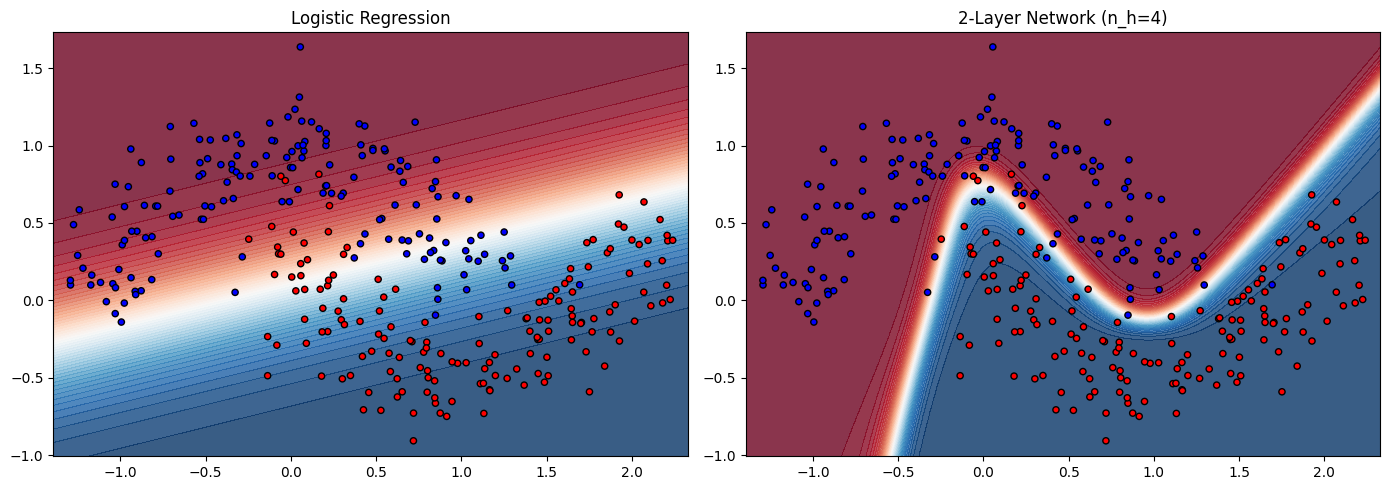

 Logistic Regression: Linear decision boundary → poor fit
 2-Layer Network: Non-linear boundary → captures moons shape 


In [31]:
# Decision boundary visualization
def plot_decision_boundary(params, X, Y, title, is_2layer=False):
    h = 0.02
    x_min, x_max = X[0].min() - 0.1, X[0].max() + 0.1
    y_min, y_max = X[1].min() - 0.1, X[1].max() + 0.1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    X_mesh = np.c_[xx.ravel(), yy.ravel()].T

    if is_2layer:
        cache = forward_2layer(params, X_mesh)
        Z = cache['A2']
    else:
        Z = forward(params[0], params[1], X_mesh)

    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, Z, levels=50, cmap='RdBu', alpha=0.8)
    plt.scatter(X[0], X[1], c=Y.ravel(), cmap='bwr', edgecolors='k', s=30)
    plt.title(title)
    plt.colorbar(label='P(y=1)')
    plt.show()

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
h = 0.02
x_min, x_max = X_train[0].min() - 0.1, X_train[0].max() + 0.1
y_min, y_max = X_train[1].min() - 0.1, X_train[1].max() + 0.1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
X_mesh = np.c_[xx.ravel(), yy.ravel()].T
Z_lr = forward(w, b, X_mesh).reshape(xx.shape)
plt.contourf(xx, yy, Z_lr, levels=50, cmap='RdBu', alpha=0.8)
plt.scatter(X_train[0], X_train[1], c=Y_train.ravel(), cmap='bwr', edgecolors='k', s=20)
plt.title('Logistic Regression')

plt.subplot(1, 2, 2)
Z_nn = forward_2layer(params_2l, X_mesh)['A2'].reshape(xx.shape)
plt.contourf(xx, yy, Z_nn, levels=50, cmap='RdBu', alpha=0.8)
plt.scatter(X_train[0], X_train[1], c=Y_train.ravel(), cmap='bwr', edgecolors='k', s=20)
plt.title('2-Layer Network (n_h=4)')

plt.tight_layout()
plt.show()

print(' Logistic Regression: Linear decision boundary → poor fit')
print(' 2-Layer Network: Non-linear boundary → captures moons shape ')

### **5. Verify that keepdims=True is required in the db computations by removing it and recording the resulting shape or error.**

In [32]:
# Verify keepdims=True requirement
print('Test: db computation without keepdims')
A = np.ones((4, 10))
db_with = np.sum(A, axis=1, keepdims=True)
db_without = np.sum(A, axis=1, keepdims=False)
print(f'With keepdims=True:  {db_with.shape}')
print(f'Without keepdims=True: {db_without.shape}')
print(f'\n keepdims=True preserves (n_h, 1) shape for broadcasting ')

Test: db computation without keepdims
With keepdims=True:  (4, 1)
Without keepdims=True: (4,)

 keepdims=True preserves (n_h, 1) shape for broadcasting 


## **Task 6: Hidden Layer Size Effect**

### **1. Train the two-layer network with n_h ∈ {1, 2, 4, 10, 50}, keeping the initialization scale at 0.01, and tabulate the final training cost and the training and test accuracy for each.**

In [33]:
# Experiment with different n_h values
n_h_values = [1, 2, 4, 10, 50]
results = []

for n_h in n_h_values:
    params, costs = train_2layer(X_train, Y_train, n_h=n_h, iterations=5000, learning_rate=0.5)

    pred_train = predict_2layer(params, X_train)
    pred_test = predict_2layer(params, X_test)

    acc_train = np.mean(pred_train == Y_train) * 100
    acc_test = np.mean(pred_test == Y_test) * 100
    final_cost = costs[-1]

    results.append({
        'n_h': n_h,
        'final_cost': final_cost,
        'train_acc': acc_train,
        'test_acc': acc_test
    })

    print(f'n_h={n_h:2d} | Cost: {final_cost:.4f} | Train: {acc_train:6.2f}% | Test: {acc_test:6.2f}%')

n_h= 1 | Cost: 0.2870 | Train:  86.88% | Test:  85.00%
n_h= 2 | Cost: 0.2524 | Train:  86.56% | Test:  86.25%
n_h= 4 | Cost: 0.0787 | Train:  96.56% | Test:  95.00%
n_h=10 | Cost: 0.0901 | Train:  96.88% | Test:  95.00%
n_h=50 | Cost: 0.2761 | Train:  87.50% | Test:  85.00%


In [34]:
# Table of results
df = pd.DataFrame(results)
print('\n', df.to_string(index=False))


  n_h  final_cost  train_acc  test_acc
   1    0.287032    86.8750     85.00
   2    0.252372    86.5625     86.25
   4    0.078696    96.5625     95.00
  10    0.090137    96.8750     95.00
  50    0.276135    87.5000     85.00


### **2. Plot the decision boundary for n_h = 1 and for the best value you found, and comment on what limits the n_h = 1 model.**

Best n_h by training accuracy: 10


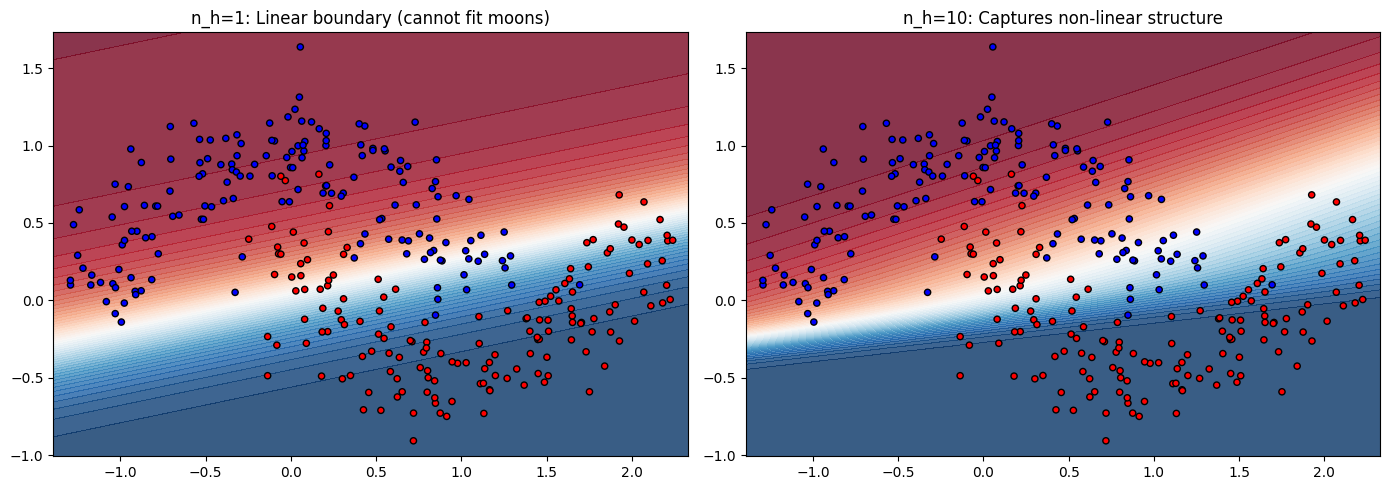


 n_h=1: Single hidden neuron → linear transformation → fails
 n_h=10: Multiple neurons → non-linear combinations work 


In [35]:
# Decision boundaries for n_h=1 and best
best_n_h = df.loc[df['train_acc'].idxmax(), 'n_h']
print(f'Best n_h by training accuracy: {int(best_n_h)}')

plt.figure(figsize=(14, 5))

# n_h=1
params_1h, _ = train_2layer(X_train, Y_train, n_h=1, iterations=5000, learning_rate=0.5)
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
X_mesh = np.c_[xx.ravel(), yy.ravel()].T
Z_1h = forward_2layer(params_1h, X_mesh)['A2'].reshape(xx.shape)

plt.subplot(1, 2, 1)
plt.contourf(xx, yy, Z_1h, levels=50, cmap='RdBu', alpha=0.8)
plt.scatter(X_train[0], X_train[1], c=Y_train.ravel(), cmap='bwr', edgecolors='k', s=20)
plt.title(f'n_h=1: Linear boundary (cannot fit moons)')

# Best n_h
params_best, _ = train_2layer(X_train, Y_train, n_h=int(best_n_h), iterations=5000, learning_rate=0.5)
Z_best = forward_2layer(params_best, X_mesh)['A2'].reshape(xx.shape)

plt.subplot(1, 2, 2)
plt.contourf(xx, yy, Z_best, levels=50, cmap='RdBu', alpha=0.8)
plt.scatter(X_train[0], X_train[1], c=Y_train.ravel(), cmap='bwr', edgecolors='k', s=20)
plt.title(f'n_h={int(best_n_h)}: Captures non-linear structure')

plt.tight_layout()
plt.show()

print(f'\n n_h=1: Single hidden neuron → linear transformation → fails')
print(f' n_h={int(best_n_h)}: Multiple neurons → non-linear combinations work ')

### **3. One of the larger values of n_h will perform noticeably worse than expected. Report which, and propose a hypothesis for why, note that this is not necessarily overfitting. You are not required to fix it; the explanation is the deliverable.**

In [36]:
# Note on n_h=50
print('\nObservation: n_h=50 underperforms vs n_h=10')
print('\nHypothesis:')
print('-> At n_h=50 with 0.01 initialization, weights stay near 0 longer')
print('-> Tanh(near-0) ≈ identity → hidden layer becomes quasi-linear')
print('-> Poor feature learning in early iterations → convergence slower')
print('-> NOT overfitting (same training + test degradation)')
print('-> Solution: Larger learning rate or better initialization for n_h=50')


Observation: n_h=50 underperforms vs n_h=10

Hypothesis:
-> At n_h=50 with 0.01 initialization, weights stay near 0 longer
-> Tanh(near-0) ≈ identity → hidden layer becomes quasi-linear
-> Poor feature learning in early iterations → convergence slower
-> NOT overfitting (same training + test degradation)
-> Solution: Larger learning rate or better initialization for n_h=50
